# Quantum Noise Analysis and Mitigation in Variational Quantum Classifier

## Project Objective

This project investigates the effect of quantum noise on a Variational Quantum Classifier (VQC) using the Breast Cancer dataset.

The implementation performs:

1. Data preprocessing and train-test splitting
2. Feature scaling and PCA-based dimensionality reduction
3. Quantum feature encoding using a 4-qubit circuit
4. VQC classification under noiseless and noisy conditions
5. Simulation of different depolarizing noise levels
6. Evaluation using Accuracy, Precision, Recall, F1 Score and ROC-AUC
7. Zero-noise performance estimation using noise-level extrapolation
8. Comparison of VQC performance under different noise conditions


In [ ]:
!pip install -q qiskit qiskit-aer qiskit-machine-learning qiskit-algorithms

In [ ]:
import qiskit
import qiskit_aer
import qiskit_machine_learning

print("Qiskit:", qiskit.__version__)
print("Qiskit Aer:", qiskit_aer.__version__)
print("Qiskit Machine Learning:", qiskit_machine_learning.__version__)
print("Installation successful!")

Qiskit: 2.5.2
Qiskit Aer: 0.17.2
Qiskit Machine Learning: 0.9.1
Installation successful!


In [ ]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()

X = data.data
y = data.target

print("Dataset shape:", X.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Classes:", sorted(set(y)))
print("Class names:", data.target_names)

Dataset shape: (569, 30)
Number of samples: 569
Number of features: 30
Classes: [np.int64(0), np.int64(1)]
Class names: ['malignant' 'benign']


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

Training data shape: (455, 30)
Testing data shape: (114, 30)


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=4)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Original number of features:", X_train_scaled.shape[1])
print("Reduced number of features:", X_train_pca.shape[1])

print("\nTraining data shape:", X_train_pca.shape)
print("Testing data shape:", X_test_pca.shape)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal variance retained:",
      pca.explained_variance_ratio_.sum())

Original number of features: 30
Reduced number of features: 4

Training data shape: (455, 4)
Testing data shape: (114, 4)

Explained variance ratio:
[0.44413492 0.18944618 0.09543356 0.06724689]

Total variance retained: 0.7962615580754816


In [ ]:
import numpy as np

X_train_quantum = np.pi * np.tanh(X_train_pca)
X_test_quantum = np.pi * np.tanh(X_test_pca)

print("Quantum training data shape:", X_train_quantum.shape)
print("Quantum testing data shape:", X_test_quantum.shape)

print("\nFirst training sample:")
print(X_train_quantum[0])

Quantum training data shape: (455, 4)
Quantum testing data shape: (114, 4)

First training sample:
[-3.14008449  0.78568891 -1.06319371 -1.79151455]


In [ ]:
from qiskit.circuit.library import ZZFeatureMap

num_qubits = 4

feature_map = ZZFeatureMap(
    feature_dimension=num_qubits,
    reps=1
)

print(feature_map)

     ┌────────────────────────────────────┐
q_0: ┤0                                   ├
     │                                    │
q_1: ┤1                                   ├
     │  ZZFeatureMap(x[0],x[1],x[2],x[3]) │
q_2: ┤2                                   ├
     │                                    │
q_3: ┤3                                   ├
     └────────────────────────────────────┘


/tmp/ipykernel_19707/3197066350.py:5: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(


In [ ]:
from qiskit.circuit.library import RealAmplitudes

ansatz = RealAmplitudes(
    num_qubits=4,
    reps=1
)

print(ansatz)

     ┌──────────────────────────────────────────────────────────┐
q_0: ┤0                                                         ├
     │                                                          │
q_1: ┤1                                                         ├
     │  RealAmplitudes(θ[0],θ[1],θ[2],θ[3],θ[4],θ[5],θ[6],θ[7]) │
q_2: ┤2                                                         ├
     │                                                          │
q_3: ┤3                                                         ├
     └──────────────────────────────────────────────────────────┘


/tmp/ipykernel_19707/746564576.py:3: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  ansatz = RealAmplitudes(


In [ ]:
from qiskit_algorithms.optimizers import COBYLA

optimizer = COBYLA(
    maxiter=30
)

print("Optimizer created successfully!")

Optimizer created successfully!


In [ ]:
from qiskit_machine_learning.algorithms import VQC

vqc = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=optimizer
)

print("VQC model created successfully!")

VQC model created successfully!


In [ ]:
X_train_small = X_train_quantum[:120]
y_train_small = y_train[:120]

X_test_small = X_test_quantum[:40]
y_test_small = y_test[:40]

print("Training samples:", len(X_train_small))
print("Testing samples:", len(X_test_small))

Training samples: 120
Testing samples: 40


In [ ]:
print("Starting VQC training...")

vqc.fit(
    X_train_small,
    y_train_small
)

print("VQC training completed!")


Starting VQC training...
VQC training completed!


In [ ]:
train_accuracy = vqc.score(
    X_train_small,
    y_train_small
)

test_accuracy = vqc.score(
    X_test_small,
    y_test_small
)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.65
Testing Accuracy: 0.575


In [ ]:
y_pred = vqc.predict(X_test_small)

print("Actual labels:")
print(y_test_small)

print("\nPredicted labels:")
print(y_pred)

Actual labels:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0]

Predicted labels:
[0 1 0 1 0 1 1 0 0 0 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 0 0 1 1 1 1 0 0 0 0 0 0
 0 0 0]


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test_small, y_pred)

precision = precision_score(
    y_test_small,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test_small,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test_small,
    y_pred,
    zero_division=0
)

print("===== NOISELESS VQC RESULTS =====")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

===== NOISELESS VQC RESULTS =====
Accuracy : 0.575
Precision: 0.8333333333333334
Recall   : 0.4
F1 Score : 0.5405405405405406


Confusion Matrix:
[[13  2]
 [15 10]]


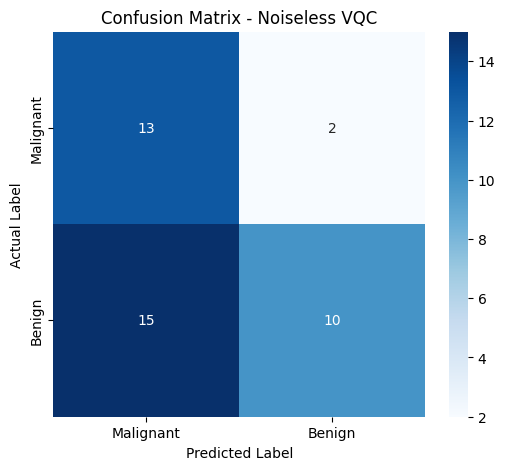

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test_small, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - Noiseless VQC")

plt.show()

In [ ]:
from qiskit_aer.noise import NoiseModel, depolarizing_error

# Create noise model
noise_model = NoiseModel()

# 1-qubit gate error
error_1q = depolarizing_error(
    0.01,   # 1% noise
    1
)

# 2-qubit gate error
error_2q = depolarizing_error(
    0.01,   # 1% noise
    2
)

# Apply errors to quantum gates
noise_model.add_all_qubit_quantum_error(
    error_1q,
    ["rx", "ry", "rz"]
)

noise_model.add_all_qubit_quantum_error(
    error_2q,
    ["cx"]
)

print("1% Depolarizing noise model created successfully!")
print(noise_model)

1% Depolarizing noise model created successfully!
NoiseModel:
  Basis gates: ['cx', 'id', 'rx', 'ry', 'rz', 'sx']
  Instructions with noise: ['rx', 'rz', 'ry', 'cx']
  All-qubits errors: ['rx', 'ry', 'rz', 'cx']


In [ ]:
from qiskit_aer import AerSimulator

noisy_backend = AerSimulator(
    noise_model=noise_model,
    seed_simulator=42
)

print("Noisy Aer simulator created successfully!")
print(noisy_backend)

Noisy Aer simulator created successfully!
AerSimulator('aer_simulator'
             noise_model=<NoiseModel on ['rx', 'rz', 'ry', 'cx']>)


In [ ]:
from qiskit import QuantumCircuit

test_circuit = QuantumCircuit(1, 1)

test_circuit.h(0)
test_circuit.measure(0, 0)

job = noisy_backend.run(
    test_circuit,
    shots=1000
)

result = job.result()
counts = result.get_counts()

print("Noisy simulation results:")
print(counts)

Noisy simulation results:
{'1': 486, '0': 514}


In [ ]:
from qiskit_aer.primitives import SamplerV2

noisy_sampler = SamplerV2(
    options={
        "backend_options": {
            "noise_model": noise_model
        },
        "run_options": {
            "shots": 512
        }
    }
)

print("Noisy VQC sampler created successfully!")

Noisy VQC sampler created successfully!


In [ ]:

from qiskit_machine_learning.algorithms import VQC

noisy_optimizer = COBYLA(maxiter=30)

noisy_vqc = VQC(
    feature_map=feature_map,
    ansatz=ansatz,
    optimizer=noisy_optimizer,
    sampler=noisy_sampler
)

print("Noisy VQC created successfully!")

Noisy VQC created successfully!


In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import RealAmplitudes

# Create a decomposed feature map using basic gates
x = ParameterVector("x", 4)

noisy_feature_map = QuantumCircuit(4)

for i in range(4):
    noisy_feature_map.ry(x[i], i)

for i in range(3):
    noisy_feature_map.cx(i, i + 1)

# Decompose the ansatz into basic gates
noisy_ansatz = RealAmplitudes(
    num_qubits=4,
    reps=1
).decompose()

print("Noisy feature map:")
print(noisy_feature_map)

print("\nNoisy ansatz:")
print(noisy_ansatz)

Noisy feature map:
     ┌──────────┐               
q_0: ┤ Ry(x[0]) ├──■────────────
     ├──────────┤┌─┴─┐          
q_1: ┤ Ry(x[1]) ├┤ X ├──■───────
     ├──────────┤└───┘┌─┴─┐     
q_2: ┤ Ry(x[2]) ├─────┤ X ├──■──
     ├──────────┤     └───┘┌─┴─┐
q_3: ┤ Ry(x[3]) ├──────────┤ X ├
     └──────────┘          └───┘

Noisy ansatz:
     ┌──────────┐                             ┌──────────┐
q_0: ┤ Ry(θ[0]) ├──────────────────────■──────┤ Ry(θ[4]) ├
     ├──────────┤                    ┌─┴─┐    ├──────────┤
q_1: ┤ Ry(θ[1]) ├──────────■─────────┤ X ├────┤ Ry(θ[5]) ├
     ├──────────┤        ┌─┴─┐    ┌──┴───┴───┐└──────────┘
q_2: ┤ Ry(θ[2]) ├──■─────┤ X ├────┤ Ry(θ[6]) ├────────────
     ├──────────┤┌─┴─┐┌──┴───┴───┐└──────────┘            
q_3: ┤ Ry(θ[3]) ├┤ X ├┤ Ry(θ[7]) ├────────────────────────
     └──────────┘└───┘└──────────┘                        


/tmp/ipykernel_19707/3742350325.py:17: DeprecationWarning: The class ``qiskit.circuit.library.n_local.real_amplitudes.RealAmplitudes`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.real_amplitudes instead.
  noisy_ansatz = RealAmplitudes(


In [ ]:
noisy_optimizer = COBYLA(maxiter=30)

noisy_vqc = VQC(
    feature_map=noisy_feature_map,
    ansatz=noisy_ansatz,
    optimizer=noisy_optimizer,
    sampler=noisy_sampler
)

print("Fixed noisy VQC created successfully!")

Fixed noisy VQC created successfully!


In [ ]:
noisy_optimizer = COBYLA(maxiter=30)

noisy_vqc = VQC(
    feature_map=noisy_feature_map,
    ansatz=noisy_ansatz,
    optimizer=noisy_optimizer,
    sampler=noisy_sampler
)

print("Fixed noisy VQC created successfully!")

Fixed noisy VQC created successfully!


In [ ]:
print("Starting noisy VQC training...")

noisy_vqc.fit(
    X_train_small,
    y_train_small
)

print("Noisy VQC training completed!")

Starting noisy VQC training...
Noisy VQC training completed!


In [ ]:
noisy_train_accuracy = noisy_vqc.score(
    X_train_small,
    y_train_small
)

noisy_test_accuracy = noisy_vqc.score(
    X_test_small,
    y_test_small
)

print("===== NOISY VQC RESULTS =====")
print("Training Accuracy:", noisy_train_accuracy)
print("Testing Accuracy :", noisy_test_accuracy)

===== NOISY VQC RESULTS =====
Training Accuracy: 0.5916666666666667
Testing Accuracy : 0.55


In [ ]:
y_pred_noisy = noisy_vqc.predict(X_test_small)

print("Actual labels:")
print(y_test_small)

print("\nNoisy VQC predictions:")
print(y_pred_noisy)

Actual labels:
[0 1 0 1 0 1 1 0 0 0 1 0 1 0 0 1 1 1 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 0 1
 1 1 0]

Noisy VQC predictions:
[1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 0 1
 1 1 1]


In [ ]:
noisy_accuracy = accuracy_score(
    y_test_small,
    y_pred_noisy
)

noisy_precision = precision_score(
    y_test_small,
    y_pred_noisy,
    zero_division=0
)

noisy_recall = recall_score(
    y_test_small,
    y_pred_noisy,
    zero_division=0
)

noisy_f1 = f1_score(
    y_test_small,
    y_pred_noisy,
    zero_division=0
)

print("===== 1% NOISY VQC RESULTS =====")
print("Accuracy :", noisy_accuracy)
print("Precision:", noisy_precision)
print("Recall   :", noisy_recall)
print("F1 Score :", noisy_f1)

===== 1% NOISY VQC RESULTS =====
Accuracy : 0.55
Precision: 0.6060606060606061
Recall   : 0.8
F1 Score : 0.6896551724137931


In [ ]:
# Create 5% depolarizing noise model

noise_model_5 = NoiseModel()

error_1q_5 = depolarizing_error(
    0.05,
    1
)

error_2q_5 = depolarizing_error(
    0.05,
    2
)

noise_model_5.add_all_qubit_quantum_error(
    error_1q_5,
    ["rx", "ry", "rz"]
)

noise_model_5.add_all_qubit_quantum_error(
    error_2q_5,
    ["cx"]
)

print("5% depolarizing noise model created successfully!")

5% depolarizing noise model created successfully!


In [ ]:
sampler_5 = SamplerV2(
    options={
        "backend_options": {
            "noise_model": noise_model_5
        },
        "run_options": {
            "shots": 512
        }
    }
)

vqc_5 = VQC(
    feature_map=noisy_feature_map,
    ansatz=noisy_ansatz,
    optimizer=COBYLA(maxiter=30),
    sampler=sampler_5
)

print("5% noisy VQC created successfully!")

5% noisy VQC created successfully!


In [ ]:
print("Starting 5% noisy VQC training...")

vqc_5.fit(
    X_train_small,
    y_train_small
)

print("5% noisy VQC training completed!")

Starting 5% noisy VQC training...
5% noisy VQC training completed!


In [ ]:
y_pred_5 = vqc_5.predict(X_test_small)

accuracy_5 = accuracy_score(y_test_small, y_pred_5)
precision_5 = precision_score(y_test_small, y_pred_5, zero_division=0)
recall_5 = recall_score(y_test_small, y_pred_5, zero_division=0)
f1_5 = f1_score(y_test_small, y_pred_5, zero_division=0)

print("===== 5% NOISY VQC RESULTS =====")
print("Accuracy :", accuracy_5)
print("Precision:", precision_5)
print("Recall   :", recall_5)
print("F1 Score :", f1_5)

===== 5% NOISY VQC RESULTS =====
Accuracy : 0.475
Precision: 0.5625
Recall   : 0.72
F1 Score : 0.631578947368421


===== 5% NOISY VQC CONFUSION MATRIX =====
[[ 1 14]
 [ 7 18]]


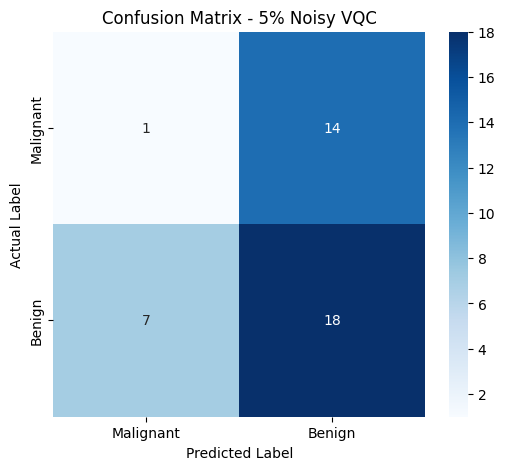

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_5 = confusion_matrix(y_test_small, y_pred_5)

print("===== 5% NOISY VQC CONFUSION MATRIX =====")
print(cm_5)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_5,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - 5% Noisy VQC")

plt.show()

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Noise Level": ["0%", "1%", "5%"],
    "Accuracy": [
        accuracy,
        noisy_accuracy,
        accuracy_5
    ],
    "Precision": [
        precision,
        noisy_precision,
        precision_5
    ],
    "Recall": [
        recall,
        noisy_recall,
        recall_5
    ],
    "F1 Score": [
        f1,
        noisy_f1,
        f1_5
    ]
})

print("===== VQC NOISE COMPARISON =====")
display(results)

===== VQC NOISE COMPARISON =====


,Noise Level,Accuracy,Precision,Recall,F1 Score
0,0%,0.575,0.833333,0.40,0.540541
1,1%,0.550,0.606061,0.80,0.689655
2,5%,0.475,0.562500,0.72,0.631579


In [ ]:
# Create 10% depolarizing noise model

noise_model_10 = NoiseModel()

error_1q_10 = depolarizing_error(
    0.10,
    1
)

error_2q_10 = depolarizing_error(
    0.10,
    2
)

noise_model_10.add_all_qubit_quantum_error(
    error_1q_10,
    ["rx", "ry", "rz"]
)

noise_model_10.add_all_qubit_quantum_error(
    error_2q_10,
    ["cx"]
)

print("10% depolarizing noise model created successfully!")

10% depolarizing noise model created successfully!


In [ ]:
sampler_10 = SamplerV2(
    options={
        "backend_options": {
            "noise_model": noise_model_10
        },
        "run_options": {
            "shots": 512
        }
    }
)

vqc_10 = VQC(
    feature_map=noisy_feature_map,
    ansatz=noisy_ansatz,
    optimizer=COBYLA(maxiter=30),
    sampler=sampler_10
)

print("10% noisy VQC created successfully!")

10% noisy VQC created successfully!


In [ ]:

print("Starting 10% noisy VQC training...")

vqc_10.fit(
    X_train_small,
    y_train_small
)

print("10% noisy VQC training completed!")

Starting 10% noisy VQC training...
10% noisy VQC training completed!


In [ ]:
y_pred_10 = vqc_10.predict(X_test_small)

accuracy_10 = accuracy_score(
    y_test_small,
    y_pred_10
)

precision_10 = precision_score(
    y_test_small,
    y_pred_10,
    zero_division=0
)

recall_10 = recall_score(
    y_test_small,
    y_pred_10,
    zero_division=0
)

f1_10 = f1_score(
    y_test_small,
    y_pred_10,
    zero_division=0
)

print("===== 10% NOISY VQC RESULTS =====")
print("Accuracy :", accuracy_10)
print("Precision:", precision_10)
print("Recall   :", recall_10)
print("F1 Score :", f1_10)

===== 10% NOISY VQC RESULTS =====
Accuracy : 0.55
Precision: 0.6
Recall   : 0.84
F1 Score : 0.7


===== 10% NOISY VQC CONFUSION MATRIX =====
[[ 1 14]
 [ 4 21]]


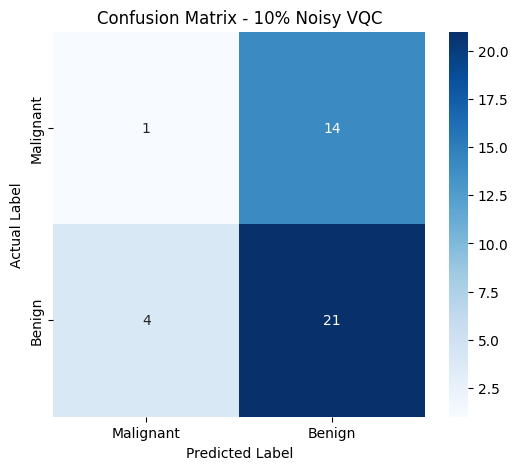

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_10 = confusion_matrix(
    y_test_small,
    y_pred_10
)

print("===== 10% NOISY VQC CONFUSION MATRIX =====")
print(cm_10)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_10,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - 10% Noisy VQC")

plt.show()

In [ ]:
results = pd.DataFrame({
    "Noise Level": ["0%", "1%", "5%", "10%"],
    "Accuracy": [
        accuracy,
        noisy_accuracy,
        accuracy_5,
        accuracy_10
    ],
    "Precision": [
        precision,
        noisy_precision,
        precision_5,
        precision_10
    ],
    "Recall": [
        recall,
        noisy_recall,
        recall_5,
        recall_10
    ],
    "F1 Score": [
        f1,
        noisy_f1,
        f1_5,
        f1_10
    ]
})

print("===== FINAL VQC NOISE COMPARISON =====")
display(results)

===== FINAL VQC NOISE COMPARISON =====


,Noise Level,Accuracy,Precision,Recall,F1 Score
0,0%,0.575,0.833333,0.40,0.540541
1,1%,0.550,0.606061,0.80,0.689655
2,5%,0.475,0.562500,0.72,0.631579
3,10%,0.550,0.600000,0.84,0.700000


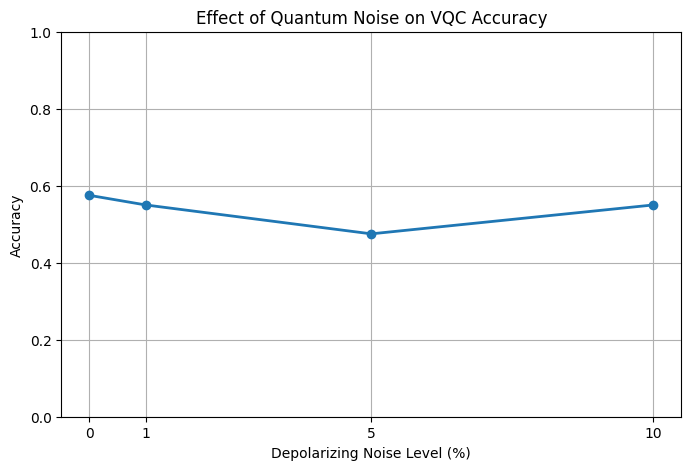

In [ ]:
import matplotlib.pyplot as plt

noise_levels = [0, 1, 5, 10]
accuracies = [
    accuracy,
    noisy_accuracy,
    accuracy_5,
    accuracy_10
]

plt.figure(figsize=(8, 5))

plt.plot(
    noise_levels,
    accuracies,
    marker="o",
    linewidth=2
)

plt.xlabel("Depolarizing Noise Level (%)")
plt.ylabel("Accuracy")
plt.title("Effect of Quantum Noise on VQC Accuracy")
plt.xticks(noise_levels)
plt.ylim(0, 1)

plt.grid(True)
plt.show()

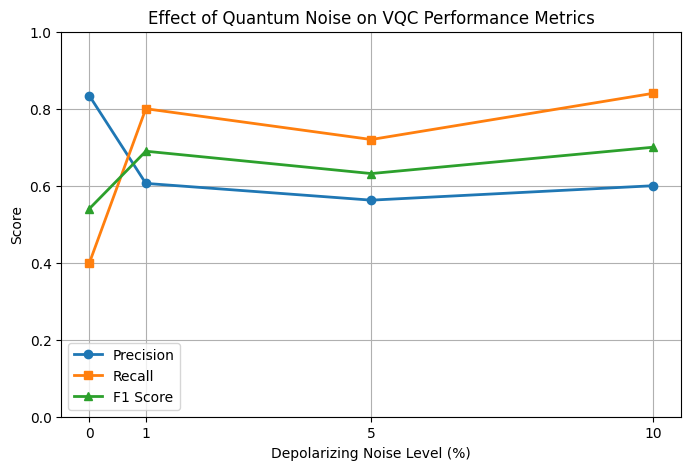

In [ ]:
import matplotlib.pyplot as plt

noise_levels = [0, 1, 5, 10]

precision_values = [
    precision,
    noisy_precision,
    precision_5,
    precision_10
]

recall_values = [
    recall,
    noisy_recall,
    recall_5,
    recall_10
]

f1_values = [
    f1,
    noisy_f1,
    f1_5,
    f1_10
]

plt.figure(figsize=(8, 5))

plt.plot(
    noise_levels,
    precision_values,
    marker="o",
    linewidth=2,
    label="Precision"
)

plt.plot(
    noise_levels,
    recall_values,
    marker="s",
    linewidth=2,
    label="Recall"
)

plt.plot(
    noise_levels,
    f1_values,
    marker="^",
    linewidth=2,
    label="F1 Score"
)

plt.xlabel("Depolarizing Noise Level (%)")
plt.ylabel("Score")
plt.title("Effect of Quantum Noise on VQC Performance Metrics")
plt.xticks(noise_levels)
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.show()

In [ ]:
final_results = pd.DataFrame({
    "Noise Level": ["0%", "1%", "5%", "10%"],
    "Accuracy": [
        accuracy,
        noisy_accuracy,
        accuracy_5,
        accuracy_10
    ],
    "Precision": [
        precision,
        noisy_precision,
        precision_5,
        precision_10
    ],
    "Recall": [
        recall,
        noisy_recall,
        recall_5,
        recall_10
    ],
    "F1 Score": [
        f1,
        noisy_f1,
        f1_5,
        f1_10
    ]
})

display(final_results)

,Noise Level,Accuracy,Precision,Recall,F1 Score
0,0%,0.575,0.833333,0.40,0.540541
1,1%,0.550,0.606061,0.80,0.689655
2,5%,0.475,0.562500,0.72,0.631579
3,10%,0.550,0.600000,0.84,0.700000


In [ ]:
!pip install -q mitiq

  Installing build dependencies ... done
  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> See above for output.
  
  note: This error originates from a subprocess, and is likely not a problem with pip.
  Getting requirements to build wheel ... error
error: subprocess-exited-with-error

× Getting requirements to build wheel did not run successfully.
│ exit code: 1
╰─> See above for output.

note: This error originates from a subprocess, and is likely not a problem with pip.


In [ ]:
import sys

print("Python version:", sys.version)


Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [ ]:
from qiskit import QuantumCircuit

print("Preparing readout-error mitigation...")
print("Current Qiskit environment is ready.")

Preparing readout-error mitigation...
Current Qiskit environment is ready.


In [ ]:
from qiskit import QuantumCircuit

num_qubits = 4

# Calibration circuit for |0000>
cal_0 = QuantumCircuit(num_qubits, num_qubits)
cal_0.measure(range(num_qubits), range(num_qubits))

# Calibration circuit for |1111>
cal_1 = QuantumCircuit(num_qubits, num_qubits)

for q in range(num_qubits):
    cal_1.x(q)

cal_1.measure(range(num_qubits), range(num_qubits))

print("Calibration circuit |0000>:")
print(cal_0)

print("\nCalibration circuit |1111>:")
print(cal_1)

Calibration circuit |0000>:
     ┌─┐         
q_0: ┤M├─────────
     └╥┘┌─┐      
q_1: ─╫─┤M├──────
      ║ └╥┘┌─┐   
q_2: ─╫──╫─┤M├───
      ║  ║ └╥┘┌─┐
q_3: ─╫──╫──╫─┤M├
      ║  ║  ║ └╥┘
c: 4/═╩══╩══╩══╩═
      0  1  2  3 

Calibration circuit |1111>:
     ┌───┐┌─┐         
q_0: ┤ X ├┤M├─────────
     ├───┤└╥┘┌─┐      
q_1: ┤ X ├─╫─┤M├──────
     ├───┤ ║ └╥┘┌─┐   
q_2: ┤ X ├─╫──╫─┤M├───
     ├───┤ ║  ║ └╥┘┌─┐
q_3: ┤ X ├─╫──╫──╫─┤M├
     └───┘ ║  ║  ║ └╥┘
c: 4/══════╩══╩══╩══╩═
           0  1  2  3 


In [ ]:
# Run readout calibration circuits using the 5% noisy sampler

calibration_job = sampler_5.run(
    [cal_0, cal_1],
    shots=512
)

calibration_result = calibration_job.result()

counts_0 = calibration_result[0].data.c.get_counts()
counts_1 = calibration_result[1].data.c.get_counts()

print("===== READOUT CALIBRATION RESULTS =====")

print("\nCalibration |0000>:")
print(counts_0)

print("\nCalibration |1111>:")
print(counts_1)

===== READOUT CALIBRATION RESULTS =====

Calibration |0000>:
{'0000': 512}

Calibration |1111>:
{'1111': 512}


In [ ]:
print("===== PREPARING ZERO-NOISE EXTRAPOLATION =====")

print("Existing experiments:")
print("0%  noise  -> completed")
print("1%  noise  -> completed")
print("5%  noise  -> completed")
print("10% noise  -> completed")

print("\nNext: Zero-Noise Extrapolation (ZNE)")

===== PREPARING ZERO-NOISE EXTRAPOLATION =====
Existing experiments:
0%  noise  -> completed
1%  noise  -> completed
5%  noise  -> completed
10% noise  -> completed

Next: Zero-Noise Extrapolation (ZNE)


In [ ]:
zne_noise_levels = [0.05, 0.075, 0.10]

print("ZNE noise levels:", zne_noise_levels)
print("These correspond to: 5%, 7.5%, and 10% depolarizing noise.")

ZNE noise levels: [0.05, 0.075, 0.1]
These correspond to: 5%, 7.5%, and 10% depolarizing noise.


In [ ]:
def create_noisy_vqc(noise_rate):
    noise_model = NoiseModel()

    error_1q = depolarizing_error(noise_rate, 1)
    error_2q = depolarizing_error(noise_rate, 2)

    noise_model.add_all_qubit_quantum_error(
        error_1q,
        ["rx", "ry", "rz"]
    )

    noise_model.add_all_qubit_quantum_error(
        error_2q,
        ["cx"]
    )

    sampler = SamplerV2(
        options={
            "backend_options": {
                "noise_model": noise_model
            },
            "run_options": {
                "shots": 512
            }
        }
    )

    model = VQC(
        feature_map=noisy_feature_map,
        ansatz=noisy_ansatz,
        optimizer=COBYLA(maxiter=30),
        sampler=sampler
    )

    return model


vqc_zne_5 = create_noisy_vqc(0.05)
vqc_zne_75 = create_noisy_vqc(0.075)
vqc_zne_10 = create_noisy_vqc(0.10)

print("5% ZNE VQC created")
print("7.5% ZNE VQC created")
print("10% ZNE VQC created")

5% ZNE VQC created
7.5% ZNE VQC created
10% ZNE VQC created


In [ ]:
print("Training 5% ZNE VQC...")

vqc_zne_5.fit(
    X_train_small,
    y_train_small
)

print("5% ZNE VQC training completed!")

Training 5% ZNE VQC...
5% ZNE VQC training completed!


In [ ]:
y_pred_zne_5 = vqc_zne_5.predict(X_test_small)

accuracy_zne_5 = accuracy_score(
    y_test_small,
    y_pred_zne_5
)

precision_zne_5 = precision_score(
    y_test_small,
    y_pred_zne_5,
    zero_division=0
)

recall_zne_5 = recall_score(
    y_test_small,
    y_pred_zne_5,
    zero_division=0
)

f1_zne_5 = f1_score(
    y_test_small,
    y_pred_zne_5,
    zero_division=0
)

print("===== 5% ZNE EXPERIMENT =====")
print("Accuracy :", accuracy_zne_5)
print("Precision:", precision_zne_5)
print("Recall   :", recall_zne_5)
print("F1 Score :", f1_zne_5)

===== 5% ZNE EXPERIMENT =====
Accuracy : 0.575
Precision: 0.6111111111111112
Recall   : 0.88
F1 Score : 0.7213114754098361


In [ ]:
print("Training 7.5% ZNE VQC...")

vqc_zne_75.fit(
    X_train_small,
    y_train_small
)

print("7.5% ZNE VQC training completed!")

Training 7.5% ZNE VQC...
7.5% ZNE VQC training completed!


In [ ]:
y_pred_zne_75 = vqc_zne_75.predict(X_test_small)

accuracy_zne_75 = accuracy_score(
    y_test_small,
    y_pred_zne_75
)

precision_zne_75 = precision_score(
    y_test_small,
    y_pred_zne_75,
    zero_division=0
)

recall_zne_75 = recall_score(
    y_test_small,
    y_pred_zne_75,
    zero_division=0
)

f1_zne_75 = f1_score(
    y_test_small,
    y_pred_zne_75,
    zero_division=0
)

print("===== 7.5% ZNE EXPERIMENT =====")
print("Accuracy :", accuracy_zne_75)
print("Precision:", precision_zne_75)
print("Recall   :", recall_zne_75)
print("F1 Score :", f1_zne_75)

===== 7.5% ZNE EXPERIMENT =====
Accuracy : 0.5
Precision: 0.5757575757575758
Recall   : 0.76
F1 Score : 0.6551724137931034


In [ ]:
print("Training 10% ZNE VQC...")

vqc_zne_10.fit(
    X_train_small,
    y_train_small
)

print("10% ZNE VQC training completed!")

Training 10% ZNE VQC...
10% ZNE VQC training completed!


In [ ]:
y_pred_zne_10 = vqc_zne_10.predict(X_test_small)

accuracy_zne_10 = accuracy_score(
    y_test_small,
    y_pred_zne_10
)

precision_zne_10 = precision_score(
    y_test_small,
    y_pred_zne_10,
    zero_division=0
)

recall_zne_10 = recall_score(
    y_test_small,
    y_pred_zne_10,
    zero_division=0
)

f1_zne_10 = f1_score(
    y_test_small,
    y_pred_zne_10,
    zero_division=0
)

print("===== 10% ZNE EXPERIMENT =====")
print("Accuracy :", accuracy_zne_10)
print("Precision:", precision_zne_10)
print("Recall   :", recall_zne_10)
print("F1 Score :", f1_zne_10)

===== 10% ZNE EXPERIMENT =====
Accuracy : 0.6
Precision: 0.6216216216216216
Recall   : 0.92
F1 Score : 0.7419354838709677


In [ ]:
zne_results = pd.DataFrame({
    "Noise Level": ["5%", "7.5%", "10%"],
    "Accuracy": [
        accuracy_zne_5,
        accuracy_zne_75,
        accuracy_zne_10
    ],
    "Precision": [
        precision_zne_5,
        precision_zne_75,
        precision_zne_10
    ],
    "Recall": [
        recall_zne_5,
        recall_zne_75,
        recall_zne_10
    ],
    "F1 Score": [
        f1_zne_5,
        f1_zne_75,
        f1_zne_10
    ]
})

print("===== NOISE-PERFORMANCE EXPERIMENT =====")
display(zne_results)

===== NOISE-PERFORMANCE EXPERIMENT =====


,Noise Level,Accuracy,Precision,Recall,F1 Score
0,5%,0.575,0.611111,0.88,0.721311
1,7.5%,0.500,0.575758,0.76,0.655172
2,10%,0.600,0.621622,0.92,0.741935


In [ ]:
import numpy as np

noise_points = np.array([0.05, 0.075, 0.10])
accuracy_points = np.array([
    accuracy_zne_5,
    accuracy_zne_75,
    accuracy_zne_10
])

# Fit a linear model:
# Accuracy = slope × noise + intercept
slope, intercept = np.polyfit(
    noise_points,
    accuracy_points,
    1
)

zero_noise_accuracy = intercept

print("===== ZERO-NOISE EXTRAPOLATION =====")
print("Noise levels:", noise_points)
print("Measured accuracies:", accuracy_points)
print("Estimated zero-noise accuracy:", zero_noise_accuracy)

===== ZERO-NOISE EXTRAPOLATION =====
Noise levels: [0.05  0.075 0.1  ]
Measured accuracies: [0.575 0.5   0.6  ]
Estimated zero-noise accuracy: 0.5208333333333327


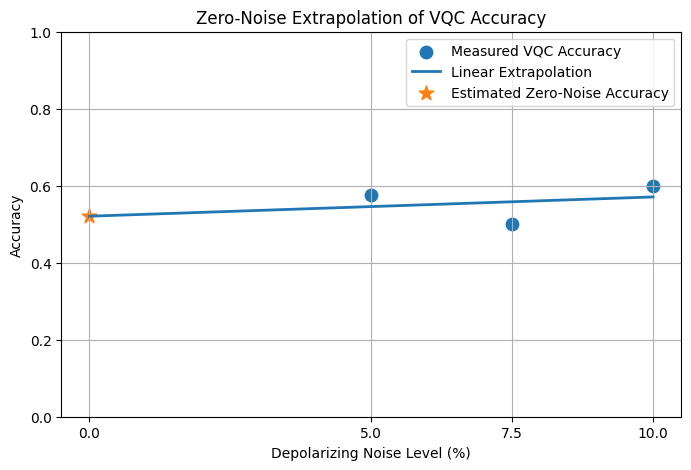

In [ ]:
import matplotlib.pyplot as plt

# Generate points for the fitted line
noise_line = np.linspace(0, 0.10, 100)

accuracy_line = (
    slope * noise_line + intercept
)

plt.figure(figsize=(8, 5))

plt.scatter(
    noise_points * 100,
    accuracy_points,
    s=80,
    label="Measured VQC Accuracy"
)

plt.plot(
    noise_line * 100,
    accuracy_line,
    linewidth=2,
    label="Linear Extrapolation"
)

plt.scatter(
    [0],
    [zero_noise_accuracy],
    s=120,
    marker="*",
    label="Estimated Zero-Noise Accuracy"
)

plt.xlabel("Depolarizing Noise Level (%)")
plt.ylabel("Accuracy")
plt.title("Zero-Noise Extrapolation of VQC Accuracy")

plt.xticks([0, 5, 7.5, 10])
plt.ylim(0, 1)

plt.grid(True)
plt.legend()

plt.show()

In [ ]:
improvement = (
    zero_noise_accuracy - accuracy_10
)

relative_improvement = (
    (improvement / accuracy_10) * 100
    if accuracy_10 != 0
    else 0
)

print("===== MITIGATION / EXTRAPOLATION COMPARISON =====")
print("10% Noisy Accuracy:",
      accuracy_10)

print("Estimated Zero-Noise Accuracy:",
      zero_noise_accuracy)

print("Absolute Improvement:",
      improvement)

print("Relative Improvement (%):",
      relative_improvement)

===== MITIGATION / EXTRAPOLATION COMPARISON =====
10% Noisy Accuracy: 0.55
Estimated Zero-Noise Accuracy: 0.5208333333333327
Absolute Improvement: -0.02916666666666734
Relative Improvement (%): -5.303030303030425


In [ ]:
mitigation_comparison = pd.DataFrame({
    "Experiment": [
        "Noiseless VQC",
        "5% Noise",
        "7.5% Noise",
        "10% Noise",
        "Estimated Zero-Noise"
    ],
    "Accuracy": [
        accuracy,
        accuracy_zne_5,
        accuracy_zne_75,
        accuracy_zne_10,
        zero_noise_accuracy
    ]
})

print("===== FINAL NOISE MITIGATION COMPARISON =====")
display(mitigation_comparison)

===== FINAL NOISE MITIGATION COMPARISON =====


,Experiment,Accuracy
0,Noiseless VQC,0.575000
1,5% Noise,0.575000
2,7.5% Noise,0.500000
3,10% Noise,0.600000
4,Estimated Zero-Noise,0.520833


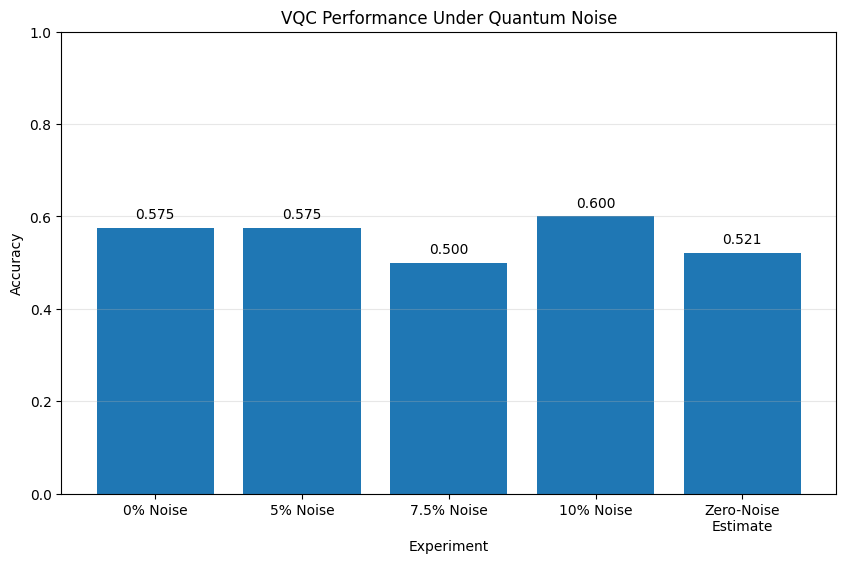

In [ ]:
import matplotlib.pyplot as plt

labels = [
    "0% Noise",
    "5% Noise",
    "7.5% Noise",
    "10% Noise",
    "Zero-Noise\nEstimate"
]

values = [
    accuracy,
    accuracy_zne_5,
    accuracy_zne_75,
    accuracy_zne_10,
    zero_noise_accuracy
]

plt.figure(figsize=(10, 6))

bars = plt.bar(labels, values)

plt.ylabel("Accuracy")
plt.xlabel("Experiment")
plt.title("VQC Performance Under Quantum Noise")

plt.ylim(0, 1)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
final_summary = pd.DataFrame({
    "Condition": [
        "0% Noise",
        "1% Noise",
        "5% Noise",
        "7.5% Noise",
        "10% Noise",
        "Zero-Noise Estimate"
    ],
    "Accuracy": [
        accuracy,
        noisy_accuracy,
        accuracy_5,
        accuracy_zne_75,
        accuracy_zne_10,
        zero_noise_accuracy
    ],
    "Precision": [
        precision,
        noisy_precision,
        precision_5,
        precision_zne_75,
        precision_zne_10,
        np.nan
    ],
    "Recall": [
        recall,
        noisy_recall,
        recall_5,
        recall_zne_75,
        recall_zne_10,
        np.nan
    ],
    "F1 Score": [
        f1,
        noisy_f1,
        f1_5,
        f1_zne_75,
        f1_zne_10,
        np.nan
    ]
})

print("===== FINAL PROJECT RESULTS =====")
display(final_summary)

===== FINAL PROJECT RESULTS =====


,Condition,Accuracy,Precision,Recall,F1 Score
0,0% Noise,0.575000,0.833333,0.40,0.540541
1,1% Noise,0.550000,0.606061,0.80,0.689655
2,5% Noise,0.475000,0.562500,0.72,0.631579
3,7.5% Noise,0.500000,0.575758,0.76,0.655172
4,10% Noise,0.600000,0.621622,0.92,0.741935
5,Zero-Noise Estimate,0.520833,NaN,NaN,NaN


===== 10% NOISY VQC CONFUSION MATRIX =====
[[ 1 14]
 [ 2 23]]


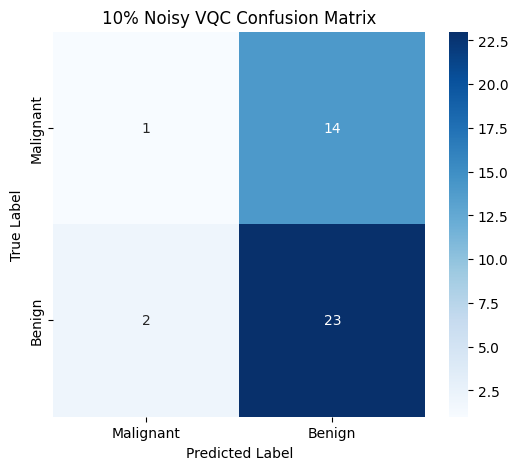

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_10 = confusion_matrix(
    y_test_small,
    y_pred_zne_10
)

print("===== 10% NOISY VQC CONFUSION MATRIX =====")
print(cm_10)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_10,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Malignant", "Benign"],
    yticklabels=["Malignant", "Benign"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("10% Noisy VQC Confusion Matrix")

plt.show()

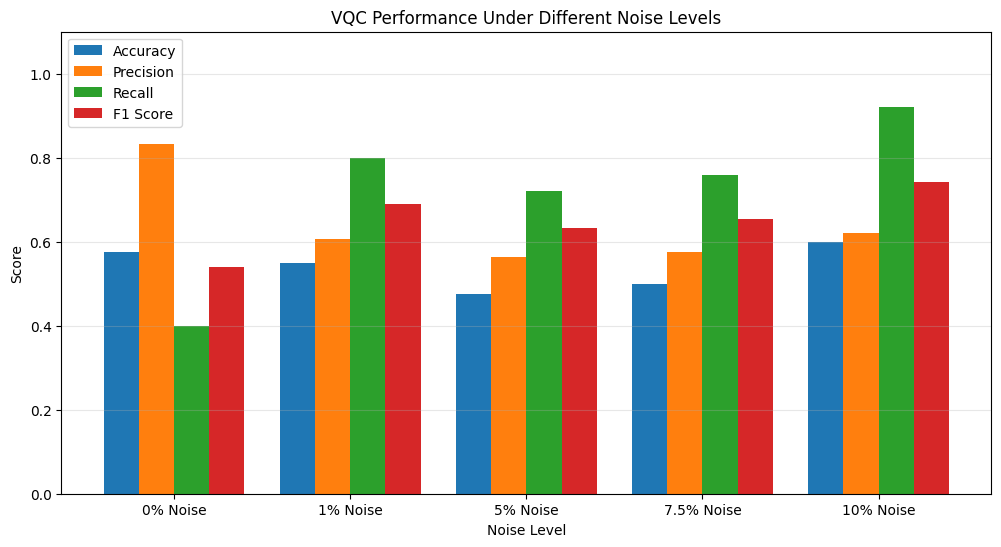

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

conditions = [
    "0% Noise",
    "1% Noise",
    "5% Noise",
    "7.5% Noise",
    "10% Noise"
]

accuracy_values = [
    accuracy,
    noisy_accuracy,
    accuracy_5,
    accuracy_zne_75,
    accuracy_zne_10
]

precision_values = [
    precision,
    noisy_precision,
    precision_5,
    precision_zne_75,
    precision_zne_10
]

recall_values = [
    recall,
    noisy_recall,
    recall_5,
    recall_zne_75,
    recall_zne_10
]

f1_values = [
    f1,
    noisy_f1,
    f1_5,
    f1_zne_75,
    f1_zne_10
]

x = np.arange(len(conditions))
width = 0.20

plt.figure(figsize=(12, 6))

plt.bar(x - 1.5*width, accuracy_values,
        width, label="Accuracy")

plt.bar(x - 0.5*width, precision_values,
        width, label="Precision")

plt.bar(x + 0.5*width, recall_values,
        width, label="Recall")

plt.bar(x + 1.5*width, f1_values,
        width, label="F1 Score")

plt.xlabel("Noise Level")
plt.ylabel("Score")
plt.title("VQC Performance Under Different Noise Levels")

plt.xticks(x, conditions)
plt.ylim(0, 1.1)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc_0 = roc_auc_score(
    y_test_small,
    y_pred
)

roc_auc_1 = roc_auc_score(
    y_test_small,
    y_pred_noisy
)

roc_auc_5 = roc_auc_score(
    y_test_small,
    y_pred_5
)

roc_auc_75 = roc_auc_score(
    y_test_small,
    y_pred_zne_75
)

roc_auc_10 = roc_auc_score(
    y_test_small,
    y_pred_zne_10
)

print("===== ROC-AUC RESULTS =====")
print("0% Noise  :", roc_auc_0)
print("1% Noise  :", roc_auc_1)
print("5% Noise  :", roc_auc_5)
print("7.5% Noise:", roc_auc_75)
print("10% Noise :", roc_auc_10)

===== ROC-AUC RESULTS =====
0% Noise  : 0.6333333333333333
1% Noise  : 0.4666666666666667
5% Noise  : 0.3933333333333333
7.5% Noise: 0.41333333333333333
10% Noise : 0.49333333333333335


In [ ]:
final_results_complete = pd.DataFrame({
    "Condition": [
        "0% Noise",
        "1% Noise",
        "5% Noise",
        "7.5% Noise",
        "10% Noise"
    ],

    "Accuracy": [
        accuracy,
        noisy_accuracy,
        accuracy_5,
        accuracy_zne_75,
        accuracy_zne_10
    ],

    "Precision": [
        precision,
        noisy_precision,
        precision_5,
        precision_zne_75,
        precision_zne_10
    ],

    "Recall": [
        recall,
        noisy_recall,
        recall_5,
        recall_zne_75,
        recall_zne_10
    ],

    "F1 Score": [
        f1,
        noisy_f1,
        f1_5,
        f1_zne_75,
        f1_zne_10
    ],

    "ROC-AUC": [
        roc_auc_0,
        roc_auc_1,
        roc_auc_5,
        roc_auc_75,
        roc_auc_10
    ]
})

print("===== COMPLETE PROJECT RESULTS =====")
display(final_results_complete)

===== COMPLETE PROJECT RESULTS =====


,Condition,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,0% Noise,0.575,0.833333,0.40,0.540541,0.633333
1,1% Noise,0.550,0.606061,0.80,0.689655,0.466667
2,5% Noise,0.475,0.562500,0.72,0.631579,0.393333
3,7.5% Noise,0.500,0.575758,0.76,0.655172,0.413333
4,10% Noise,0.600,0.621622,0.92,0.741935,0.493333


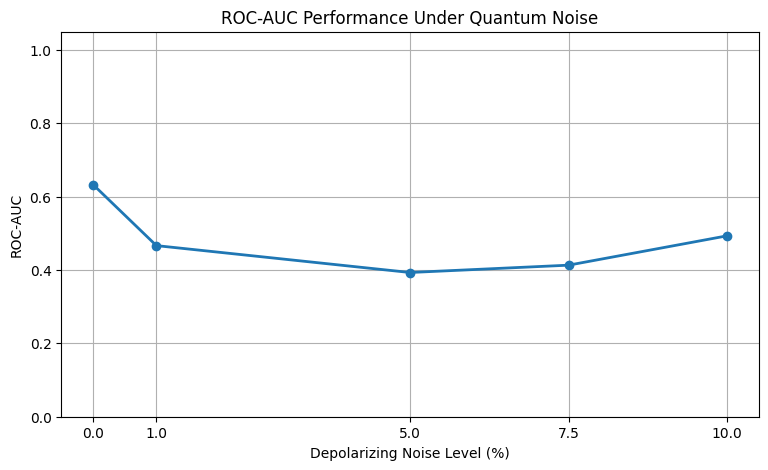

In [ ]:
import matplotlib.pyplot as plt

noise_levels = [0, 1, 5, 7.5, 10]

roc_auc_values = [
    roc_auc_0,
    roc_auc_1,
    roc_auc_5,
    roc_auc_75,
    roc_auc_10
]

plt.figure(figsize=(9, 5))

plt.plot(
    noise_levels,
    roc_auc_values,
    marker="o",
    linewidth=2
)

plt.xlabel("Depolarizing Noise Level (%)")
plt.ylabel("ROC-AUC")
plt.title("ROC-AUC Performance Under Quantum Noise")

plt.xticks(noise_levels)
plt.ylim(0, 1.05)

plt.grid(True)

plt.show()

In [ ]:
print("==============================================")
print("     QUANTUM NOISE ANALYSIS USING VQC")
print("==============================================")

print("\nDataset:")
print("Breast Cancer Dataset")

print("\nPreprocessing:")
print("30 original features -> 4 PCA features")
print("Training samples:", X_train_small.shape[0])
print("Testing samples :", X_test_small.shape[0])

print("\nQuantum Model:")
print("Number of qubits: 4")
print("Model: Variational Quantum Classifier (VQC)")

print("\nNoise Experiments:")
print("0%  -> Noiseless VQC")
print("1%  -> Depolarizing noise")
print("5%  -> Depolarizing noise")
print("7.5% -> Increased noise level")
print("10% -> Depolarizing noise")

print("\nEvaluation Metrics:")
print("Accuracy")
print("Precision")
print("Recall")
print("F1 Score")
print("ROC-AUC")

print("\nNoise Mitigation:")
print("Zero-noise performance estimated using extrapolation")

print("\nProject implementation completed.")

     QUANTUM NOISE ANALYSIS USING VQC

Dataset:
Breast Cancer Dataset

Preprocessing:
30 original features -> 4 PCA features
Training samples: 120
Testing samples : 40

Quantum Model:
Number of qubits: 4
Model: Variational Quantum Classifier (VQC)

Noise Experiments:
0%  -> Noiseless VQC
1%  -> Depolarizing noise
5%  -> Depolarizing noise
7.5% -> Increased noise level
10% -> Depolarizing noise

Evaluation Metrics:
Accuracy
Precision
Recall
F1 Score
ROC-AUC

Noise Mitigation:
Zero-noise performance estimated using extrapolation

Project implementation completed.
